# K-Nearest Neighbors (KNN): A Supervised Learning Method

In this lecture, we learn **K-nearest neighbors (KNN)**, one of the simplest and most intuitive **supervised learning** methods.

We will use two input variables:

- `AnnualIncome`
- `AnnualSpending`

to predict which group a customer belongs to:

- **Low-Value Customer**
- **Mid-Value Customer**
- **High-Value Customer**

The main goal of this lecture is to understand **what makes KNN supervised**. In the next lectures (clustering and association rules), we will see **unsupervised** methods and compare them with KNN.

## Learning Objectives

By the end of this lecture, you should be able to:

- explain the difference between **supervised** and **unsupervised** learning
- explain why KNN is a **supervised learning** method, and why we must define both `X` and `y`
- explain the basic idea of **nearest neighbors** and **majority vote**
- explain what **k** means and why the choice of `k` matters
- explain why **feature scaling** is important in KNN, and the difference between `fit_transform()` and `transform()`
- explain what `fit()`, `predict()` and `kneighbors()` do in Python
- build a simple KNN model in Python and predict the class of a new customer

## 1. Supervised vs. unsupervised learning

In **supervised learning**, the data contains:

- input variables `X`
- a known output variable `y` (the "label", or the answer)

We learn from examples whose answers we already know, and then we predict the answer for a new observation.

In **unsupervised learning**, the data contains only `X`. There is **no** `y`. The goal is to discover structure in the data, such as groups of similar observations.

| | Supervised | Unsupervised |
|---|---|---|
| Is `y` in the data? | Yes | No |
| Goal | Predict `y` for a new observation | Find structure in `X` |
| Examples | Regression, **KNN (today)** | **Clustering (next lecture)**, **association rules** |

In our example:

- `X` = `AnnualIncome`, `AnnualSpending`
- `y` = `CustomerValueCategory`

Because every customer in our data already has a known category, KNN is a **supervised learning** method.

**Note:** in **KNN classification**, the target variable `y` is **categorical**. (There is also a version of KNN for numeric targets, called KNN regression, but we do not cover it here.)

## 2. The data: every customer already has a label

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Print numpy arrays with 3 decimals, to keep the outputs readable.
np.set_printoptions(precision=3, suppress=True)

In [22]:
# Create one simple customer dataset.
# The points are intentionally not perfectly separated.
# In real classification problems, classes usually overlap.

customer_df = pd.DataFrame({
    "AnnualIncome": [
        42000, 54000, 76000, 50000, 52000, 71000,
        55000, 82000, 92000, 62000, 63000, 68000,
        70000, 48000, 104000, 78000, 76000, 86000,
        85000, 88000, 70000, 58000, 57000, 98000,
        67000, 65000, 80000, 74000, 60000, 62000,
        46000, 79000, 61000, 81000, 90000, 74000
    ],
    "AnnualSpending": [
        18000, 42000, 74000, 22000, 52000, 41000,
        30000, 47000, 76000, 26000, 48000, 61000,
        34000, 36000, 83000, 29000, 50000, 64000,
        32000, 55000, 60000, 24000, 46000, 70000,
        27000, 45000, 69000, 36000, 39000, 54000,
        38000, 43000, 58000, 33000, 52000, 65000
    ],
    "CustomerValueCategory": [
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "High-Value Customer", "Mid-Value Customer",
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "Mid-Value Customer", "High-Value Customer",
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "Mid-Value Customer", "High-Value Customer",
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "Mid-Value Customer", "High-Value Customer",
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "Mid-Value Customer", "High-Value Customer",
        "Low-Value Customer", "Mid-Value Customer", "High-Value Customer", "Low-Value Customer", "Mid-Value Customer", "High-Value Customer"
    ]
})

customer_df

,AnnualIncome,AnnualSpending,CustomerValueCategory
0,42000,18000,Low-Value Customer
1,54000,42000,Mid-Value Customer
2,76000,74000,High-Value Customer
3,50000,22000,Low-Value Customer
4,52000,52000,High-Value Customer
5,71000,41000,Mid-Value Customer
6,55000,30000,Low-Value Customer
7,82000,47000,Mid-Value Customer
8,92000,76000,High-Value Customer
9,62000,26000,Low-Value Customer


This is a small **hand-made dataset** created only for learning KNN.

The last column, `CustomerValueCategory`, is the **label**: the answer we already know for each customer. This column is what makes the problem **supervised**.

In [23]:
# Check how many customers are in each class.
customer_df["CustomerValueCategory"].value_counts()

,count
CustomerValueCategory,
Low-Value Customer,12
Mid-Value Customer,12
High-Value Customer,12


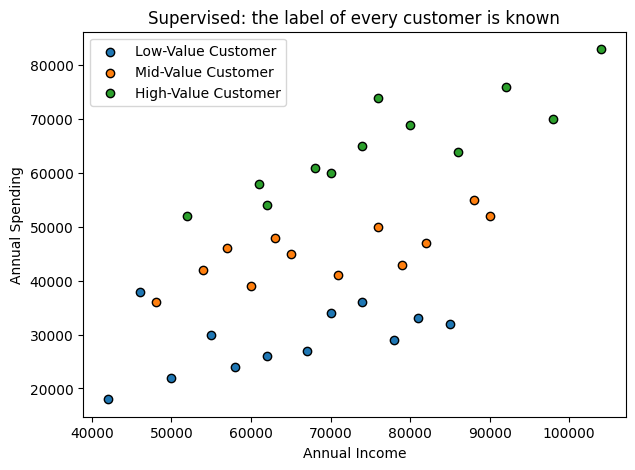

In [25]:
# One color for each class. We reuse these colors in every plot.
colors = {
    "Low-Value Customer": "tab:blue",
    "Mid-Value Customer": "tab:orange",
    "High-Value Customer": "tab:green"
}

plt.figure(figsize=(7, 5))

# Plot each customer group separately.
for category, color in colors.items():
    subset = customer_df[customer_df["CustomerValueCategory"] == category]
    plt.scatter(subset["AnnualIncome"], subset["AnnualSpending"],
                c=color, edgecolors="black", label=category)

plt.xlabel("Annual Income")
plt.ylabel("Annual Spending")
plt.title("Supervised: the label of every customer is known")
plt.legend()
plt.show()

Each dot is one customer. The **color** of the dot is the label we already know.

Customers with similar income and spending are close to each other. Notice that the three groups overlap a little. That is normal in real data.

**Looking ahead:** in the next lecture (clustering), the data will look like the plot below: the same customers, but **no labels**. The computer will have to find the groups by itself. That is **unsupervised** learning.

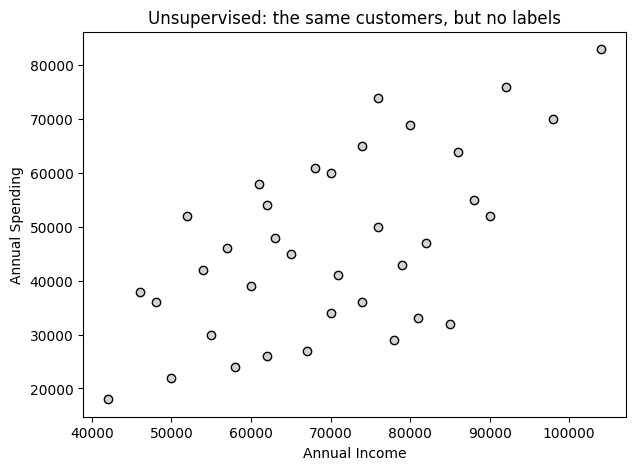

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(customer_df["AnnualIncome"], customer_df["AnnualSpending"],
            c="lightgray", edgecolors="black")
plt.xlabel("Annual Income")
plt.ylabel("Annual Spending")
plt.title("Unsupervised: the same customers, but no labels")
plt.show()

## 3. The basic idea of KNN: ask the neighbors

KNN predicts the class of a new customer by looking at the **nearest customers** in the labeled data and taking a **majority vote**.

Suppose a new customer has:

- `AnnualIncome = 77,000`
- `AnnualSpending = 55,000`

The 3 nearest customers in our data are:

- Mid-Value Customer
- High-Value Customer
- Mid-Value Customer

Two of the three neighbors are Mid-Value, so KNN predicts:

- **Mid-Value Customer**

So the main idea is:

> A new observation is classified by a majority vote of its nearest labeled neighbors.

Notice that this only works because the neighbors **have labels**. Without the labels, there would be nothing to vote with.

## 4. What does `k` mean?

The `k` in KNN is the **number of neighbors** used for the vote.

- `k = 1` → use only the 1 nearest neighbor
- `k = 3` → use the 3 nearest neighbors
- `k = 5` → use the 5 nearest neighbors

General idea:

- small `k` → the prediction depends on very few customers, so one unusual customer can change the answer
- large `k` → many customers vote, so one unusual customer matters less, but customers that are far away (and possibly from another group) also get a vote

A common choice is an **odd** value of `k`, so that a two-class vote cannot end in a tie. (With three classes a tie is still possible; in that case scikit-learn picks the class that comes first alphabetically.)

In this lecture, we use `k = 3`. In Section 7 we will see what happens when we change it.

## 5. Why do we scale the features?

KNN decides which customers are "nearest" with the ordinary distance formula:

> distance = √( (income difference)² + (spending difference)² )

The formula just adds up squared differences. It does **not** know what units the numbers are in, so whichever feature has the **bigger numbers** controls the distance.

**Example.** Suppose income is recorded in dollars but spending is recorded in *thousands* of dollars:

- Customer A: income 70,000, spending 60 (thousand)
- Customer B: income 70,000, spending 20 (thousand)
- Customer C: income 71,000, spending 60 (thousand)

distance(A, B) = 40, but distance(A, C) = 1,000. KNN would call A and B "close" even though B spends three times less, and A and C "far" even though they are nearly identical customers. Spending has been silently ignored.

The same problem appears, more mildly, whenever one feature simply varies more than another, even when both are in the same units.

**The fix: `StandardScaler`.** For each feature separately, it computes

> scaled value = (value − mean of the feature) / standard deviation of the feature

After scaling, every feature has mean 0 and standard deviation 1. A difference of "1" now means "one standard deviation" for *both* income and spending, so both features count equally in the distance.

In our dataset both variables are in dollars with a similar spread, so scaling changes little here. But it is a habit we keep for **every** distance-based method, including k-means in the next lecture.

## 6. Python: build the model and predict a new customer

### Defining `X` and `y`

In supervised learning we hand the model two things:

- **`X` — the inputs.** What we will know about a *new* customer: income and spending.
- **`y` — the answers.** The category of every customer in our data. This is the label.

For a new customer we will have `X` but not `y`. The model's job is: *given `X`, produce `y`.* To learn that job, it needs examples where both are known. That is what "supervised" means: we supervise the learning by supplying the answers.

In the next lecture, the clustering model will receive `X` only. There is no `y` to give it.

In [6]:
# X = the INPUTS: what we know about each customer (the "questions").
X = customer_df[["AnnualIncome", "AnnualSpending"]]

# y = the ANSWERS: the known category of each customer (the "label").
# Supervised learning = we give the model both the questions AND the answers.
y = customer_df["CustomerValueCategory"]

print("X shape:", X.shape)   # 36 customers, 2 input columns
print("y shape:", y.shape)   # 36 answers, one per customer

X shape: (36, 2)
y shape: (36,)


### Scaling: `fit_transform()` vs. `transform()`

`StandardScaler` has two separate jobs:

1. **`fit`** — *learn* the mean and standard deviation of each feature from the data.
2. **`transform`** — *apply* the formula (value − mean) / std, using the numbers learned in step 1.

`fit_transform()` does both in one call. We use it **once**, on the 36 customers.

Every later customer must be scaled with the **same** mean and standard deviation, so for new customers we call only `transform()`.

If we called `fit_transform()` on a new customer, the scaler would learn a *new* mean and std from that one row: the mean would be the customer itself and the std would be 0. The result would be `[0, 0]` for every new customer, which is meaningless and not comparable with the training data.

In [26]:
scaler = StandardScaler()

# fit_transform = (1) learn the mean and std of each column, (2) scale the 36 customers.
X_scaled = scaler.fit_transform(X)

# The scaler remembers what it learned:
print("Mean of each feature:", scaler.mean_)
print("Std of each feature: ", scaler.scale_)

Mean of each feature: [70111.111 46638.889]
Std of each feature:  [14908.569 16376.054]


In [8]:
# Check the formula by hand for the first customer (income 42,000, spending 18,000).
print("First customer, original:", X.iloc[0].values)
print("First customer, scaled:  ", X_scaled[0])

mean_income = scaler.mean_[0]
std_income = scaler.scale_[0]
print(f"By hand: (42000 - {mean_income:.2f}) / {std_income:.2f} = {(42000 - mean_income) / std_income:.3f}")

First customer, original: [42000 18000]
First customer, scaled:   [-1.886 -1.749]
By hand: (42000 - 70111.11) / 14908.57 = -1.886


A scaled value of −1.89 means "1.89 standard deviations *below* the average income." The scaled spending, −1.75, is read the same way. Both numbers are now on the same scale.

### What does `fit()` do?

In [9]:
# Create the KNN model with k = 3.
knn = KNeighborsClassifier(n_neighbors=3)

# fit(X, y): hand the model the inputs AND the answers. This is the supervised step.
# For KNN, fit() computes no formula and no coefficients. It simply STORES the 36 scaled
# customers together with their labels, so it can look them up when we ask for a prediction.
knn.fit(X_scaled, y)

KNeighborsClassifier(n_neighbors=3)

Compare with regression, where `fit()` estimates coefficients and the data can then be thrown away. KNN keeps the data; the data *is* the model. That is why KNN is sometimes called a **lazy learner**: `fit()` is instant, and all the work (finding neighbors, counting votes) happens later, in `predict()`.

Notice that `fit()` takes **two** arguments here: `X_scaled` **and** `y`. In the next lecture you will see `kmeans.fit(X_scaled)`, with no `y`. That one line of code is the difference between supervised and unsupervised learning.

### What does `predict()` return?

`predict()` takes a table of **scaled** inputs (one row per customer) and returns an **array** of predicted labels, one per row. Even when we pass a single customer, the result is an array with one element, so we write `[0]` to take the first (and only) label out of it.

Let's predict the new customer from Section 3: income 77,000 and spending 55,000.

A tempting shortcut is `knn.predict([[77000, 55000]])`. That is **wrong** here, because the model was trained on **scaled** data: an unscaled customer would be compared with scaled customers. So we create a DataFrame, apply the **same scaler** with `transform()`, and then predict.

In [10]:
# Create one new customer as a DataFrame with the same two column names.
new_customer = pd.DataFrame({
    "AnnualIncome": [77000],
    "AnnualSpending": [55000]
})

# Scale it with the SAME mean and std as the training data: transform only, no fit.
new_customer_scaled = scaler.transform(new_customer)
print("Scaled new customer:", new_customer_scaled)

# predict() returns one label per input row, as an array.
predicted_class = knn.predict(new_customer_scaled)
print("predict() returned:", predicted_class)
print("Predicted category:", predicted_class[0])    # [0] takes the first element

Scaled new customer: [[0.462 0.511]]
predict() returned: ['Mid-Value Customer']
Predicted category: Mid-Value Customer


### Where did the prediction come from? `kneighbors()`

`knn.kneighbors()` takes the same input as `predict()`, the scaled new customer, and returns **two arrays**, each with one row per input customer:

- `distances` — the scaled distances from the new customer to its `k` nearest training customers, closest first
- `indices` — the **row positions** of those `k` customers in the training data

Because we trained on `X_scaled`, which has the same row order as `customer_df`, these positions are also row positions in `customer_df`.

We do this in three small steps.

In [11]:
# Step 1: ask the model for the 3 nearest neighbors.
distances, indices = knn.kneighbors(new_customer_scaled)

print("distances:", distances)
print("indices:  ", indices)

distances: [[0.313 0.56  0.593]]
indices:   [[16 20  7]]


Each array has **one row**, because we asked about **one** customer.

- `indices[0]` is that row: `[16, 20, 7]`. The nearest customer is row 16 of our table, then row 20, then row 7.
- `distances[0]` is the matching row of distances: row 16 is at scaled distance 0.31, row 20 at 0.56, row 7 at 0.59.

In [12]:
# Step 2: look up those rows in the original table.
# .iloc[...] selects rows by POSITION, and indices[0] is the list of positions [16, 20, 7].
neighbors = customer_df.iloc[indices[0]]
neighbors

,AnnualIncome,AnnualSpending,CustomerValueCategory
16,76000,50000,Mid-Value Customer
20,70000,60000,High-Value Customer
7,82000,47000,Mid-Value Customer


In [13]:
# Step 3: show the distances next to the neighbors.
# .copy() makes a separate copy first, so adding a column does not change customer_df.
neighbors = neighbors.copy()
neighbors["ScaledDistance"] = distances[0].round(3)    # distances[0] = the row for our one customer
neighbors

,AnnualIncome,AnnualSpending,CustomerValueCategory,ScaledDistance
16,76000,50000,Mid-Value Customer,0.313
20,70000,60000,High-Value Customer,0.560
7,82000,47000,Mid-Value Customer,0.593


In [29]:
# The vote. predict_proba() returns the FRACTION of neighbors in each class,
# in the order of knn.classes_ (alphabetical). Again one row per input customer, so [0].

knn.predict_proba(new_customer_scaled)


#votes = pd.Series(knn.predict_proba(new_customer_scaled)[0], index=knn.classes_)
#votes

array([[0.333, 0.   , 0.667]])

Two of the three neighbors are Mid-Value customers, so the vote is 2 to 1 and KNN predicts **Mid-Value Customer**.

The plot below shows the new customer (black star) and its 3 nearest neighbors (circled).

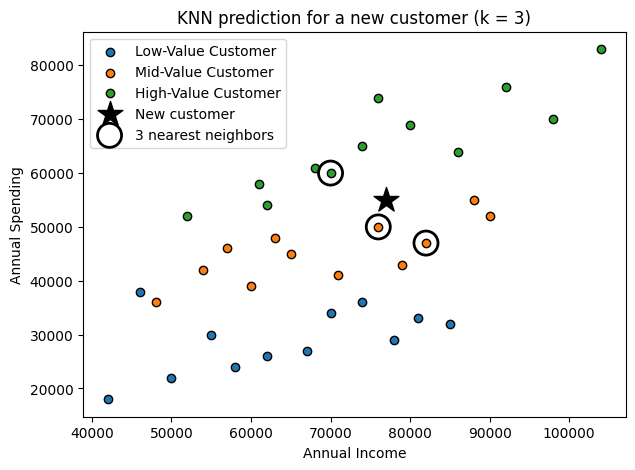

In [16]:
plt.figure(figsize=(7, 5))

for category, color in colors.items():
    subset = customer_df[customer_df["CustomerValueCategory"] == category]
    plt.scatter(subset["AnnualIncome"], subset["AnnualSpending"],
                c=color, edgecolors="black", label=category)

# The new customer.
plt.scatter(new_customer["AnnualIncome"], new_customer["AnnualSpending"],
            marker="*", s=350, c="black", label="New customer")

# Circle its 3 nearest neighbors.
plt.scatter(neighbors["AnnualIncome"], neighbors["AnnualSpending"],
            s=300, facecolors="none", edgecolors="black", linewidths=2,
            label="3 nearest neighbors")

plt.xlabel("Annual Income")
plt.ylabel("Annual Spending")
plt.title("KNN prediction for a new customer (k = 3)")
plt.legend()
plt.show()

### Predicting several customers at once

`predict()` handles many customers in one call and returns one label per row.

In [17]:
two_customers = pd.DataFrame({
    "AnnualIncome":   [47000, 90000],
    "AnnualSpending": [26000, 70000]
})

# Same recipe: transform with the SAME scaler, then predict. One label per row.

two_customers_scaled = scaler.transform(two_customers)
knn.predict(two_customers_scaled)

array(['Low-Value Customer', 'High-Value Customer'], dtype=object)

## 7. Does the choice of `k` matter?

Let's predict two customers with different values of `k`:

- our new customer from Section 6 (income 77,000, spending 55,000), who sits near the border between two groups
- a clear-cut customer (income 47,000, spending 26,000), who sits deep inside the Low-Value group

In [27]:
print("Customer near the border (income 77,000, spending 55,000):")
for k in [1, 3, 5, 7, 9, 11, 15]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_scaled, y)
    print(f"  k = {k:2d}: {knn_k.predict(new_customer_scaled)[0]}")

clear_customer = pd.DataFrame({
    "AnnualIncome": [47000],
    "AnnualSpending": [26000]
})
clear_customer_scaled = scaler.transform(clear_customer)

print()
print("Customer deep inside a group (income 47,000, spending 26,000):")
for k in [1, 3, 5, 7, 9, 11, 15]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_scaled, y)
    print(f"  k = {k:2d}: {knn_k.predict(clear_customer_scaled)[0]}")

Customer near the border (income 77,000, spending 55,000):
  k =  1: Mid-Value Customer
  k =  3: Mid-Value Customer
  k =  5: High-Value Customer
  k =  7: Mid-Value Customer
  k =  9: High-Value Customer
  k = 11: Mid-Value Customer
  k = 15: Mid-Value Customer

Customer deep inside a group (income 47,000, spending 26,000):
  k =  1: Low-Value Customer
  k =  3: Low-Value Customer
  k =  5: Low-Value Customer
  k =  7: Low-Value Customer
  k =  9: Low-Value Customer
  k = 11: Low-Value Customer
  k = 15: Low-Value Customer


### What do we observe?

For the border customer, the answer keeps flipping. Here is the vote behind each prediction:

| k | Mid votes | High votes | Prediction |
|---|---|---|---|
| 1 | 1 | 0 | Mid |
| 3 | 2 | 1 | Mid |
| 5 | 2 | 3 | High |
| 7 | 4 | 3 | Mid |
| 9 | 4 | 5 | High |
| 11 | 6 | 5 | Mid |
| 15 | 8 | 7 | Mid |

Every vote is decided by a **single vote**. This customer sits right on the border between the Mid and High groups, and each extra neighbor we let in can tip the result.

For the clear-cut customer, nothing changes: all of its close neighbors are Low-Value, so every `k` agrees.

### The lessons

1. **`k` is a real choice, not a detail.** For observations near a border between groups, `k` decides the answer. For observations deep inside a group, it hardly matters.
2. **Small `k` trusts very few customers.** With `k = 1` the prediction is a copy of one customer's label. If that customer is unusual, the prediction is wrong.
3. **Large `k` lets far-away customers vote.** With `k = 15`, almost half of the data votes on every prediction, including customers that are not really similar. At the extreme, `k = 36` means everyone votes on everything, and every new customer gets the same answer: the model stops looking at the new customer at all.
4. **There is no single "correct" `k`.** In practice we choose `k` by holding back some customers whose labels we know, predicting them, and counting how often each `k` is right. That is a separate topic, and we do not cover it in this lecture.

### Optional picture: small `k` vs. large `k`

Every point of the plane below is colored by the class that KNN would predict there.

- With `k = 1`, every customer sits inside a region of its own color: the model simply memorizes each customer.
- With `k = 15`, almost half of all customers vote on every prediction. Small details disappear, and several customers end up inside a region of a different color.

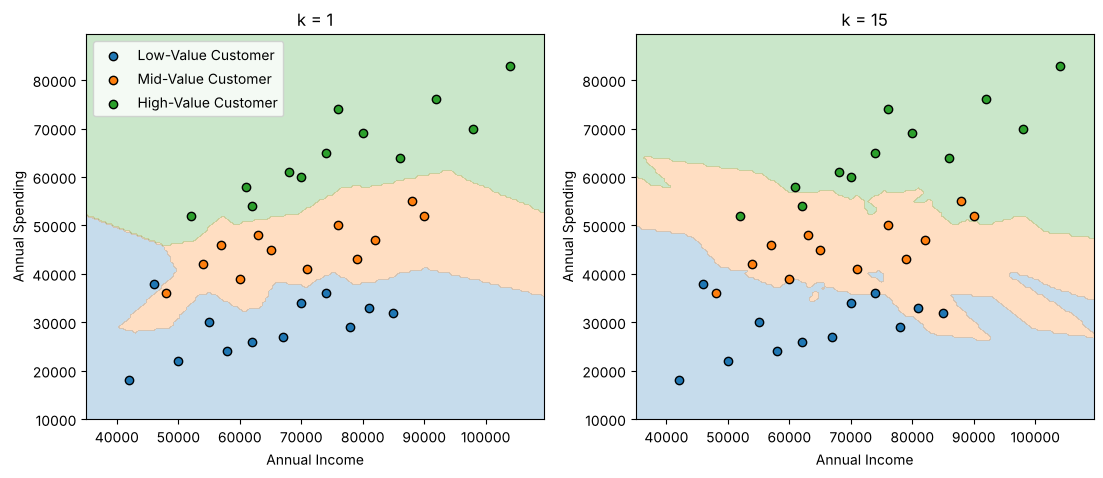

In [ ]:
from matplotlib.colors import ListedColormap

# A grid of (income, spending) values that covers the plot.
income_grid, spending_grid = np.meshgrid(
    np.arange(35000, 110000, 500),
    np.arange(10000, 90000, 500)
)
grid = pd.DataFrame({
    "AnnualIncome": income_grid.ravel(),
    "AnnualSpending": spending_grid.ravel()
})
grid_scaled = scaler.transform(grid)

class_number = {"Low-Value Customer": 0, "Mid-Value Customer": 1, "High-Value Customer": 2}
region_colors = ListedColormap(["tab:blue", "tab:orange", "tab:green"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, k in zip(axes, [1, 15]):
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_scaled, y)

    grid_pred = knn_k.predict(grid_scaled)
    grid_pred_number = np.array([class_number[p] for p in grid_pred]).reshape(income_grid.shape)

    ax.contourf(income_grid, spending_grid, grid_pred_number,
                levels=[-0.5, 0.5, 1.5, 2.5], cmap=region_colors, alpha=0.25)

    for category, color in colors.items():
        subset = customer_df[customer_df["CustomerValueCategory"] == category]
        ax.scatter(subset["AnnualIncome"], subset["AnnualSpending"],
                   c=color, edgecolors="black", label=category)

    ax.set_title(f"k = {k}")
    ax.set_xlabel("Annual Income")
    ax.set_ylabel("Annual Spending")

axes[0].legend()
plt.show()

## 8. Looking ahead: KNN vs. k-means

In the next lecture we will see **k-means clustering**. It also has a `k`, it also uses distance, and it also needs scaled features, but it is **unsupervised**. Do not mix up the two `k`'s.

| | KNN (today) | k-means (next lecture) |
|---|---|---|
| Type of learning | Supervised | Unsupervised |
| Does the data have labels `y`? | Yes | No |
| What does `fit()` receive? | `X` **and** `y` | `X` only |
| What is `k`? | Number of **neighbors** used in the vote | Number of **clusters** to find |
| What does it produce? | A predicted class for a new observation | Groups of similar observations |
| Uses distance? | Yes | Yes |
| Needs feature scaling? | Yes | Yes |

## 9. Key Points

- In **supervised** learning the data contains a known output `y`; in **unsupervised** learning it does not.
- KNN is **supervised** because every training observation already has a label. That is why we define both `X` (the inputs) and `y` (the answers).
- `fit()` simply stores the labeled observations. `predict()` finds the `k` nearest neighbors and takes a **majority vote**. `kneighbors()` shows us who those neighbors are.
- `predict()` returns an **array** with one label per input row, so we use `[0]` to read the label of a single observation.
- Because KNN uses **distance**, we **scale** the features first: `fit_transform()` on the training data **once**, then `transform()` on every new observation, so everything is scaled with the same mean and standard deviation.
- `k` is the number of neighbors. It matters most for observations near a border between groups. Small `k` trusts one or two customers; large `k` lets far-away customers vote. There is no single correct `k`.
- Next lecture: the same kind of data **without labels**, which is clustering (unsupervised).